# Cross-encoder для STS: fine-tuning xlm-roberta-base на STS Benchmark

Этап 1: английский STS Benchmark. Все параметры (модель, датасет, колонки, пути) задаются в блоке конфигурации.

## 1. Установка

In [2]:
!pip install -q datasets

In [ ]:
import torch, transformers, datasets, pandas, sklearn
print("torch", torch.__version__)
print("transformers", transformers.__version__)
print("datasets", datasets.__version__)
print("pandas", pandas.__version__)
print("sklearn", sklearn.__version__)

torch 2.11.0+cu130
transformers 5.20.1
datasets 4.8.5
pandas 2.2.3
sklearn 1.6.1


## 2. Конфигурация

In [ ]:
CFG = {
    "model_name": "xlm-roberta-base",
    "dataset_name": "mteb/stsbenchmark-sts",
    "dataset_config": None,
    "train_split": "train",
    "val_split": "validation",
    "test_split": "test",
    "text1_col": "sentence1",
    "text2_col": "sentence2",
    "label_col": "score",
    "score_max": None,
    "use_drive": True,
    "drive_mount": "/content/drive",
    "project_root": "/content/drive/MyDrive/textreuse",
    "run_name": "stsb_en_xlmr_base_cross_encoder",
    "max_length": 128,
    "train_batch_size": 16,
    "eval_batch_size": 64,
    "learning_rate": 2e-5,
    "num_epochs": 4,
    "warmup_ratio": 0.1,
    "weight_decay": 0.01,
    "fp16": True,
    "logging_steps": 50,
    "save_total_limit": 2,
    "embed_batch_size": 64,
    "n_worst": 10,
    "seed": 42,
}

In [ ]:
import os
import json
import math
import random

if CFG["use_drive"]:
    from google.colab import drive
    drive.mount(CFG["drive_mount"])

RUN_DIR = os.path.join(CFG["project_root"], CFG["run_name"])
CKPT_DIR = os.path.join(RUN_DIR, "checkpoints")
FINAL_DIR = os.path.join(RUN_DIR, "final_model")
RESULTS_DIR = os.path.join(RUN_DIR, "results")
for d in (RUN_DIR, CKPT_DIR, FINAL_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

with open(os.path.join(RUN_DIR, "config.json"), "w") as f:
    json.dump(CFG, f, indent=2)

print(RUN_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from datasets import load_dataset, DatasetDict, Value
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)
from transformers.trainer_utils import get_last_checkpoint
from sklearn.feature_extraction.text import TfidfVectorizer

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)
    set_seed(seed)

seed_everything(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

cuda Tesla T4


## 3. Загрузка данных

In [ ]:
raw = load_dataset(CFG["dataset_name"], CFG["dataset_config"]) if CFG["dataset_config"] else load_dataset(CFG["dataset_name"])
print(raw)

split_map = {"train": CFG["train_split"], "validation": CFG["val_split"], "test": CFG["test_split"]}
col_map = {CFG["text1_col"]: "sentence1", CFG["text2_col"]: "sentence2", CFG["label_col"]: "score"}

ds = DatasetDict({k: raw[v] for k, v in split_map.items()})
ds = ds.select_columns(list(col_map.keys()))
ds = ds.rename_columns({k: v for k, v in col_map.items() if k != v})
ds = ds.filter(lambda x: x["sentence1"] is not None and x["sentence2"] is not None and x["score"] is not None)
ds = ds.cast_column("score", Value("float32"))
print(ds)

DatasetDict({
    train: Dataset({
        features: ['split', 'genre', 'dataset', 'year', 'sid', 'score', 'sentence1', 'sentence2'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['split', 'genre', 'dataset', 'year', 'sid', 'score', 'sentence1', 'sentence2'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['split', 'genre', 'dataset', 'year', 'sid', 'score', 'sentence1', 'sentence2'],
        num_rows: 1379
    })
})
DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'score'],
        num_rows: 1379
    })
})


In [ ]:
all_scores = np.concatenate([np.asarray(list(ds[s]["score"]), dtype=np.float64) for s in ds])
obs_min, obs_max = float(all_scores.min()), float(all_scores.max())
SCORE_SCALE = float(CFG["score_max"]) if CFG["score_max"] else (5.0 if obs_max > 1.0 else 1.0)
print(f"Наблюдаемый диапазон оценок: [{obs_min:.3f}, {obs_max:.3f}]")
print(f"Шкала: 0–{SCORE_SCALE:g}, для обучения оценки делятся на {SCORE_SCALE:g}")

ds = ds.map(lambda b: {"label": [s / SCORE_SCALE for s in b["score"]]}, batched=True)
ds = ds.cast_column("label", Value("float32"))

for s in ds:
    lab = np.asarray(list(ds[s]["label"]))
    print(s, f"label ∈ [{lab.min():.3f}, {lab.max():.3f}]")

Наблюдаемый диапазон оценок: [0.000, 5.000]
Шкала: 0–5, для обучения оценки делятся на 5
train label ∈ [0.000, 1.000]
validation label ∈ [0.000, 1.000]
test label ∈ [0.000, 1.000]


In [ ]:
def sts_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return {
        "spearman": float(spearmanr(y_true, y_pred)[0]),
        "pearson": float(pearsonr(y_true, y_pred)[0]),
    }

results = []

def add_result(model_name, split, metrics):
    results.append({"model": model_name, "split": split, **metrics})
    print(f"{model_name:35s} {split:10s} spearman={metrics['spearman']:.4f} pearson={metrics['pearson']:.4f}")

## 4. EDA

In [ ]:
sizes = pd.DataFrame({"split": list(ds.keys()), "n_pairs": [len(ds[s]) for s in ds]})
display(sizes)

score_stats = pd.DataFrame({s: pd.Series(list(ds[s]["score"])).describe() for s in ds}).T
display(score_stats)

,split,n_pairs
0,train,5749
1,validation,1500
2,test,1379


,count,mean,std,min,25%,50%,75%,max
train,5749.0,2.700999,1.464398,0.0,1.500,3.00,3.8,5.0
validation,1500.0,2.363908,1.500486,0.0,1.000,2.55,3.6,5.0
test,1379.0,2.607917,1.525517,0.0,1.315,2.80,3.8,5.0


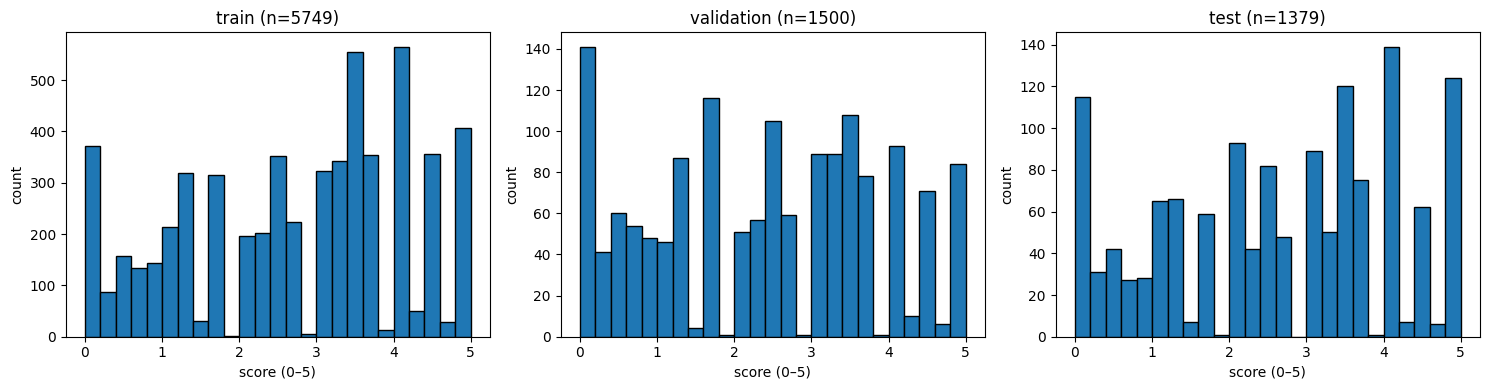

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
bins = np.linspace(0, SCORE_SCALE, 26)
for ax, s in zip(axes, ds):
    ax.hist(list(ds[s]["score"]), bins=bins, edgecolor="black")
    ax.set_title(f"{s} (n={len(ds[s])})")
    ax.set_xlabel(f"score (0–{SCORE_SCALE:g})")
    ax.set_ylabel("count")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "eda_score_hist.png"), dpi=150)
plt.show()

,count,mean,std,min,50%,90%,95%,99%,max
split,,,,,,,,,
test,2758.0,13.534808,7.615825,3.0,11.0,25.0,31.0,39.0,48.0
train,11498.0,14.325187,8.163626,3.0,12.0,27.0,33.0,42.0,82.0
validation,3000.0,15.924667,7.983247,3.0,14.0,27.0,32.0,39.0,50.0


,count,mean,std,min,50%,90%,95%,99%,max
split,,,,,,,,,
test,1379.0,31.069616,14.718779,10.0,26.0,54.0,66.0,81.0,97.0
train,5749.0,32.650374,15.827166,13.0,27.0,58.0,68.0,85.0,152.0
validation,1500.0,35.849333,15.145898,13.0,32.0,57.0,66.0,78.0,98.0


Доля пар длиннее max_length=128 токенов, %:
split
test          0.000
train         0.035
validation    0.000


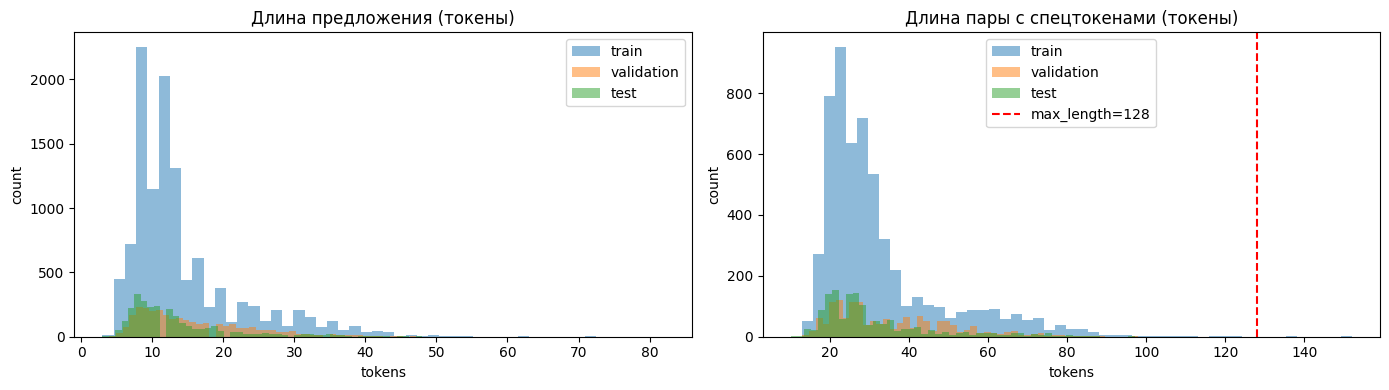

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"])

len_rows = []
for s in ds:
    l1 = [len(x) for x in tokenizer(list(ds[s]["sentence1"]), add_special_tokens=False)["input_ids"]]
    l2 = [len(x) for x in tokenizer(list(ds[s]["sentence2"]), add_special_tokens=False)["input_ids"]]
    lp = [len(x) for x in tokenizer(list(ds[s]["sentence1"]), list(ds[s]["sentence2"]))["input_ids"]]
    len_rows.append(pd.DataFrame({"split": s, "sent_len": l1 + l2, "pair_len": lp + [np.nan] * (len(l1 + l2) - len(lp))}))
lens = pd.concat(len_rows, ignore_index=True)

display(lens.groupby("split")["sent_len"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
display(lens.dropna().groupby("split")["pair_len"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
over = lens.dropna().groupby("split")["pair_len"].apply(lambda x: float((x > CFG["max_length"]).mean() * 100))
print(f"Доля пар длиннее max_length={CFG['max_length']} токенов, %:")
print(over.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for s in ds:
    sub = lens[lens["split"] == s]
    axes[0].hist(sub["sent_len"], bins=50, alpha=0.5, label=s)
    axes[1].hist(sub["pair_len"].dropna(), bins=50, alpha=0.5, label=s)
axes[0].set_title("Длина предложения (токены)")
axes[1].set_title("Длина пары с спецтокенами (токены)")
axes[1].axvline(CFG["max_length"], color="red", linestyle="--", label=f"max_length={CFG['max_length']}")
for ax in axes:
    ax.set_xlabel("tokens")
    ax.set_ylabel("count")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "eda_token_lengths.png"), dpi=150)
plt.show()

## 5. Baseline'ы

### 5.1 TF-IDF cosine similarity (vectorizer обучается только на train)

In [ ]:
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 1), norm="l2")
tfidf.fit(list(ds["train"]["sentence1"]) + list(ds["train"]["sentence2"]))

def tfidf_cosine(split):
    a = tfidf.transform(list(ds[split]["sentence1"]))
    b = tfidf.transform(list(ds[split]["sentence2"]))
    return np.asarray(a.multiply(b).sum(axis=1)).ravel()

for s in ("validation", "test"):
    sim = tfidf_cosine(s)
    add_result("TF-IDF cosine", s, sts_metrics(list(ds[s]["score"]), sim * SCORE_SCALE))

TF-IDF cosine                       validation spearman=0.7195 pearson=0.7203
TF-IDF cosine                       test       spearman=0.6406 pearson=0.6584


### 5.2 xlm-roberta-base без обучения: mean pooling + cosine

In [ ]:
encoder = AutoModel.from_pretrained(CFG["model_name"]).to(DEVICE).eval()

@torch.no_grad()
def mean_pool_embed(sentences, batch_size):
    out = []
    for i in range(0, len(sentences), batch_size):
        batch = tokenizer(sentences[i:i + batch_size], padding=True, truncation=True, max_length=CFG["max_length"], return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            hidden = encoder(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        emb = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        out.append(emb.float().cpu())
    return torch.cat(out)

for s in ("validation", "test"):
    e1 = mean_pool_embed(list(ds[s]["sentence1"]), CFG["embed_batch_size"])
    e2 = mean_pool_embed(list(ds[s]["sentence2"]), CFG["embed_batch_size"])
    sim = torch.nn.functional.cosine_similarity(e1, e2).numpy()
    add_result(f"{CFG['model_name']} (no fine-tuning)", s, sts_metrics(list(ds[s]["score"]), sim))

del encoder
torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


xlm-roberta-base (no fine-tuning)   validation spearman=0.5361 pearson=0.4330
xlm-roberta-base (no fine-tuning)   test       spearman=0.4073 pearson=0.3273


## 6. Обучение cross-encoder

In [ ]:
def tokenize_pairs(batch):
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True, max_length=CFG["max_length"])

tok_ds = ds.map(tokenize_pairs, batched=True, remove_columns=["sentence1", "sentence2", "score"])
print(tok_ds)

collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    preds = np.asarray(preds).reshape(-1)
    labels = np.asarray(labels).reshape(-1)
    return sts_metrics(labels * SCORE_SCALE, preds * SCORE_SCALE)

Map:   0%|          | 0/5749 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1379 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1379
    })
})


In [ ]:
seed_everything(CFG["seed"])

model = AutoModelForSequenceClassification.from_pretrained(
    CFG["model_name"],
    num_labels=1,
    problem_type="regression",
)

steps_per_epoch = math.ceil(len(tok_ds["train"]) / CFG["train_batch_size"])
total_steps = steps_per_epoch * CFG["num_epochs"]
warmup_steps = int(round(CFG["warmup_ratio"] * total_steps))
print(f"steps/epoch={steps_per_epoch} total={total_steps} warmup={warmup_steps}")

args = TrainingArguments(
    output_dir=CKPT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=CFG["logging_steps"],
    per_device_train_batch_size=CFG["train_batch_size"],
    per_device_eval_batch_size=CFG["eval_batch_size"],
    learning_rate=CFG["learning_rate"],
    num_train_epochs=CFG["num_epochs"],
    warmup_steps=warmup_steps,
    weight_decay=CFG["weight_decay"],
    lr_scheduler_type="linear",
    fp16=CFG["fp16"] and torch.cuda.is_available(),
    load_best_model_at_end=True,
    metric_for_best_model="spearman",
    greater_is_better=True,
    save_total_limit=CFG["save_total_limit"],
    seed=CFG["seed"],
    data_seed=CFG["seed"],
    report_to="none",
    dataloader_num_workers=2,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tok_ds["train"],
    eval_dataset=tok_ds["validation"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


steps/epoch=360 total=1440 warmup=144


In [ ]:
last_ckpt = get_last_checkpoint(CKPT_DIR)
print("Продолжение с checkpoint:" if last_ckpt else "Обучение с нуля", last_ckpt or "")

train_result = trainer.train(resume_from_checkpoint=last_ckpt)
print(train_result)
print("Лучший checkpoint:", trainer.state.best_model_checkpoint, "spearman =", trainer.state.best_metric)

Обучение с нуля 


Epoch,Training Loss,Validation Loss,Spearman,Pearson
1,0.041684,0.036962,0.854300,0.856907
2,0.031860,0.021335,0.870305,0.873612
3,0.026573,0.020552,0.876453,0.879625
4,0.017092,0.020812,0.876380,0.879186


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1440, training_loss=0.03902936689555645, metrics={'train_runtime': 284.2695, 'train_samples_per_second': 80.895, 'train_steps_per_second': 5.066, 'total_flos': 834075626035446.0, 'train_loss': 0.03902936689555645, 'epoch': 4.0})
Лучший checkpoint: /content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/checkpoints/checkpoint-1080 spearman = 0.8764530567820806


In [ ]:
trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
with open(os.path.join(FINAL_DIR, "training_info.json"), "w") as f:
    json.dump({
        "best_model_checkpoint": trainer.state.best_model_checkpoint,
        "best_val_spearman": trainer.state.best_metric,
        "score_scale": SCORE_SCALE,
        "config": CFG,
    }, f, indent=2)

history = pd.DataFrame(trainer.state.log_history)
history.to_csv(os.path.join(RESULTS_DIR, "train_log_history.csv"), index=False)
eval_hist = history.dropna(subset=["eval_spearman"])[["epoch", "eval_loss", "eval_spearman", "eval_pearson"]].reset_index(drop=True)
display(eval_hist)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,eval_loss,eval_spearman,eval_pearson
0,1.0,0.036962,0.854300,0.856907
1,2.0,0.021335,0.870305,0.873612
2,3.0,0.020552,0.876453,0.879625
3,4.0,0.020812,0.876380,0.879186


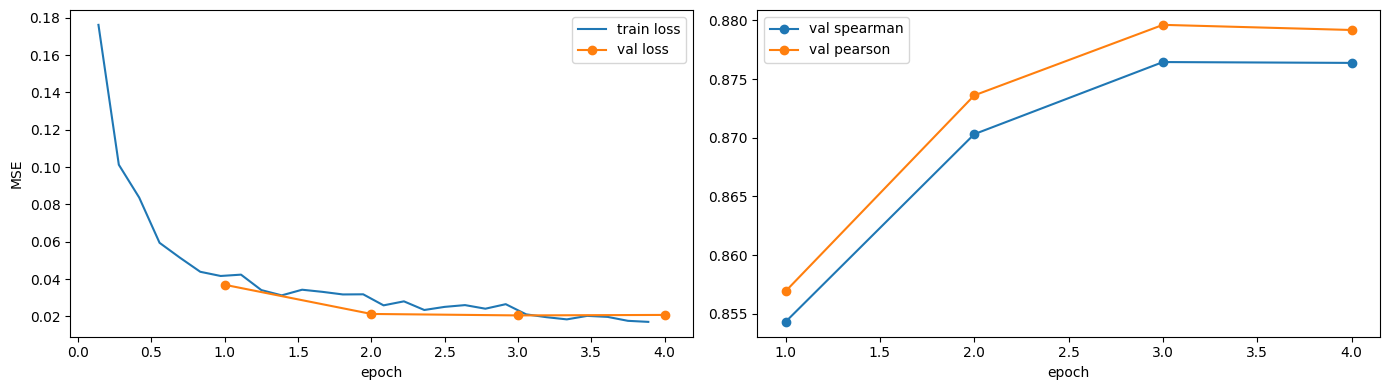

In [ ]:
train_loss = history.dropna(subset=["loss"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(train_loss["epoch"], train_loss["loss"], label="train loss")
axes[0].plot(eval_hist["epoch"], eval_hist["eval_loss"], marker="o", label="val loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[1].plot(eval_hist["epoch"], eval_hist["eval_spearman"], marker="o", label="val spearman")
axes[1].plot(eval_hist["epoch"], eval_hist["eval_pearson"], marker="o", label="val pearson")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "training_curves.png"), dpi=150)
plt.show()

## 7. Оценка финальной модели (test используется один раз)

In [ ]:
CE_NAME = f"{CFG['model_name']} cross-encoder (fine-tuned)"

val_out = trainer.predict(tok_ds["validation"])
val_pred = np.asarray(val_out.predictions).reshape(-1) * SCORE_SCALE
add_result(CE_NAME, "validation", sts_metrics(list(ds["validation"]["score"]), val_pred))

test_out = trainer.predict(tok_ds["test"])
test_pred = np.asarray(test_out.predictions).reshape(-1) * SCORE_SCALE
add_result(CE_NAME, "test", sts_metrics(list(ds["test"]["score"]), test_pred))

xlm-roberta-base cross-encoder (fine-tuned) validation spearman=0.8765 pearson=0.8796


xlm-roberta-base cross-encoder (fine-tuned) test       spearman=0.8226 pearson=0.8352


In [ ]:
res_df = pd.DataFrame(results)
table = res_df.pivot_table(index="model", columns="split", values=["spearman", "pearson"], sort=False)
table = table.reindex(columns=[(m, s) for m in ("spearman", "pearson") for s in ("validation", "test")])
table.columns = [f"{s}_{m}" for m, s in table.columns]
table = table.reindex(res_df["model"].drop_duplicates().tolist())
table.to_csv(os.path.join(RESULTS_DIR, "results_table.csv"))
display(table.round(4))

,validation_spearman,test_spearman,validation_pearson,test_pearson
model,,,,
TF-IDF cosine,0.7195,0.6406,0.7203,0.6584
xlm-roberta-base (no fine-tuning),0.5361,0.4073,0.4330,0.3273
xlm-roberta-base cross-encoder (fine-tuned),0.8765,0.8226,0.8796,0.8352


In [ ]:
pred_df = pd.DataFrame({
    "sentence1": list(ds["test"]["sentence1"]),
    "sentence2": list(ds["test"]["sentence2"]),
    "score": np.asarray(list(ds["test"]["score"]), dtype=np.float64),
    "pred": test_pred,
})
pred_df["pred_clipped"] = pred_df["pred"].clip(0, SCORE_SCALE)
pred_df["abs_error"] = (pred_df["pred_clipped"] - pred_df["score"]).abs()
pred_df.to_csv(os.path.join(RESULTS_DIR, "test_predictions.csv"), index=False)
print(f"MAE (0–{SCORE_SCALE:g}) = {pred_df['abs_error'].mean():.4f}")

MAE (0–5) = 0.6261


In [ ]:
worst = pred_df.sort_values("abs_error", ascending=False).head(CFG["n_worst"]).reset_index(drop=True)
for i, r in worst.iterrows():
    print(f"#{i + 1}  true={r['score']:.2f}  pred={r['pred_clipped']:.2f}  |err|={r['abs_error']:.2f}")
    print(f"   S1: {r['sentence1']}")
    print(f"   S2: {r['sentence2']}")
    print()

#1  true=4.00  pred=0.78  |err|=3.22
   S1: I'm going to be very direct here.
   S2: I'm going to be blunt, here: You don't.

#2  true=5.00  pred=1.93  |err|=3.07
   S1: There are two things to consider:
   S2: A couple things to consider:

#3  true=5.00  pred=1.99  |err|=3.01
   S1: A few more point to think about:
   S2: A few things to think about:

#4  true=0.00  pred=2.92  |err|=2.92
   S1: Work into it slowly.
   S2: It seems to work.

#5  true=0.00  pred=2.64  |err|=2.64
   S1: The answer to both questions is: Yes.
   S2: To directly answer the two questions in your title.

#6  true=5.00  pred=2.46  |err|=2.54
   S1: Take a look at these:
   S2: Take a look at this: 

#7  true=5.00  pred=2.47  |err|=2.53
   S1: I'm afraid we are out of luck in this one.
   S2: I think this is one of those things where you are just out of luck.

#8  true=1.40  pred=3.89  |err|=2.49
   S1: Someone is on a blanket.
   S2: The person is making a blanket.

#9  true=5.00  pred=2.53  |err|=2.47
   S1: 

## 8. Сохранённые результаты

In [ ]:
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        print(os.path.join(root, fn))
print(FINAL_DIR, sorted(os.listdir(FINAL_DIR)))

/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/results/eda_score_hist.png
/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/results/eda_token_lengths.png
/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/results/results_table.csv
/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/results/test_predictions.csv
/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/results/train_log_history.csv
/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/results/training_curves.png
/content/drive/MyDrive/textreuse/stsb_en_xlmr_base_cross_encoder/final_model ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin', 'training_info.json']
